In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Download monthly copper prices from FRED
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=PCOPPUSDM"

df = pd.read_csv(url)

df = df.rename(columns={
    "observation_date": "Date",
    "PCOPPUSDM": "Copper_Price"
})

df["Date"] = pd.to_datetime(df["Date"])
df["Copper_Price"] = pd.to_numeric(
    df["Copper_Price"], errors="coerce"
)

df = (
    df.dropna(subset=["Date", "Copper_Price"])
      .sort_values("Date")
      .drop_duplicates(subset=["Date"])
      .reset_index(drop=True)
)

print("Dataset dimensions:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nData types and missing values:")
df.info()
print(df.isnull().sum())

Dataset dimensions: (415, 2)

First five rows:


,Date,Copper_Price
0,1992-01-01,2150.579629
1,1992-02-01,2208.892259
2,1992-03-01,2231.785510
3,1992-04-01,2214.166816
4,1992-05-01,2219.315056



Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          415 non-null    datetime64[ns]
 1   Copper_Price  415 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 6.6 KB
Date            0
Copper_Price    0
dtype: int64


Date range: 1992-01-01 00:00:00 to 2026-07-01 00:00:00

Summary statistics:


count      415.000000
mean      5310.802881
std       2989.959011
min       1377.376087
25%       2225.550283
50%       5718.150000
75%       7674.651190
max      13552.040909
Name: Copper_Price, dtype: float64

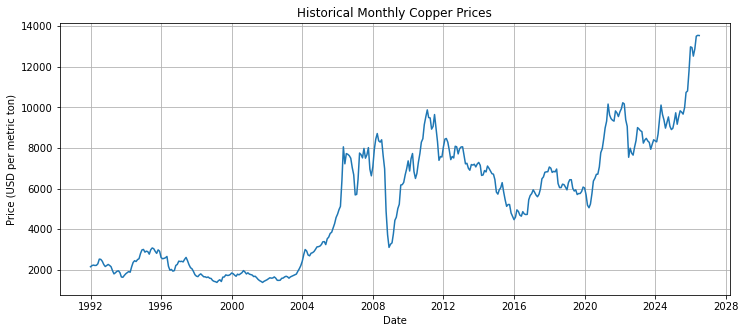

In [2]:
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("\nSummary statistics:")
display(df["Copper_Price"].describe())

plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Copper_Price"])
plt.title("Historical Monthly Copper Prices")
plt.xlabel("Date")
plt.ylabel("Price (USD per metric ton)")
plt.grid(True)
plt.show()

In [3]:
data = df.copy()

# Historical price features
for lag in [1, 2, 3, 6, 12]:
    data[f"Price_Lag_{lag}"] = data["Copper_Price"].shift(lag)

# Rolling averages using only information available at time t
data["Rolling_Mean_3"] = (
    data["Copper_Price"].rolling(3).mean()
)
data["Rolling_Mean_12"] = (
    data["Copper_Price"].rolling(12).mean()
)

# Target: copper price one month into the future
data["Target_Next_Month"] = data["Copper_Price"].shift(-1)

# Remove rows without sufficient history or a future target
data = data.dropna().reset_index(drop=True)

features = [
    "Price_Lag_1",
    "Price_Lag_2",
    "Price_Lag_3",
    "Price_Lag_6",
    "Price_Lag_12",
    "Rolling_Mean_3",
    "Rolling_Mean_12"
]

X = data[features]
y = data["Target_Next_Month"]

display(data[["Date"] + features + ["Target_Next_Month"]].head())
print("Number of usable observations:", len(data))

,Date,Price_Lag_1,Price_Lag_2,Price_Lag_3,Price_Lag_6,Price_Lag_12,Rolling_Mean_3,Rolling_Mean_12,Target_Next_Month
0,1993-01-01,2211.950287,2161.789094,2262.456962,2527.285022,2150.579629,2212.651117,2294.281757,2212.181393
1,1993-02-01,2264.213971,2211.950287,2161.789094,2513.469985,2208.892259,2229.448550,2294.555851,2152.380201
2,1993-03-01,2212.181393,2264.213971,2211.950287,2419.614182,2231.785510,2209.591855,2287.938742,1953.620602
3,1993-04-01,2152.380201,2212.181393,2264.213971,2262.456962,2214.166816,2106.060732,2266.226558,1799.351698
4,1993-05-01,1953.620602,2152.380201,2212.181393,2161.789094,2219.315056,1968.450834,2231.229611,1857.870708


Number of usable observations: 402


In [4]:
split_idx = int(len(data) * 0.80)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

test_dates = data["Date"].iloc[split_idx:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("First test feature date:", test_dates.iloc[0])
print("First test target month:", test_dates.iloc[0] + pd.offsets.MonthBegin(1))

Training observations: 321
Testing observations: 81
First test feature date: 2019-10-01 00:00:00
First test target month: 2019-11-01 00:00:00


In [5]:
data["Price_Current"] = data["Copper_Price"]

In [6]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

results = []
predictions = {}

# Baseline: next month's price equals this month's observed price
baseline_pred = data["Copper_Price"].iloc[split_idx:].to_numpy()

predictions["Naive Baseline"] = baseline_pred

results.append({
    "Model": "Naive Baseline",
    "MAE": mean_absolute_error(y_test, baseline_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, baseline_pred)),
    "R2": r2_score(y_test, baseline_pred)
})

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE")

display(results_df.round(2))


,Model,MAE,RMSE,R2
0,Naive Baseline,331.19,432.64,0.95
1,Linear Regression,336.51,436.69,0.95
3,Gradient Boosting,1021.53,1529.52,0.34
2,Random Forest,1155.91,1732.95,0.15


In [8]:
tscv = TimeSeriesSplit(n_splits=5)

# Random Forest hyperparameter grid
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, None],
    "min_samples_leaf": [1, 3, 5]
}

rf_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=rf_grid,
    scoring="neg_mean_squared_error",
    cv=tscv,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)
print("Best CV RMSE:",
      np.sqrt(-rf_search.best_score_))

Best Random Forest parameters:
{'max_depth': 3, 'min_samples_leaf': 3, 'n_estimators': 200}
Best CV RMSE: 1017.8205223821689


In [9]:
gb_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [1, 2, 3]
}

gb_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=gb_grid,
    scoring="neg_mean_squared_error",
    cv=tscv,
    n_jobs=-1
)

gb_search.fit(X_train, y_train)

print("Best Gradient Boosting parameters:")
print(gb_search.best_params_)
print("Best CV RMSE:",
      np.sqrt(-gb_search.best_score_))

Best Gradient Boosting parameters:
{'learning_rate': 0.05, 'max_depth': 1, 'n_estimators': 100}
Best CV RMSE: 1048.3055940121396


In [10]:
tuned_models = {
    "Tuned Random Forest": rf_search.best_estimator_,
    "Tuned Gradient Boosting": gb_search.best_estimator_
}

for name, model in tuned_models.items():
    pred = model.predict(X_test)
    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = (
    pd.DataFrame(results)
    .drop_duplicates(subset="Model", keep="last")
    .sort_values("RMSE")
)

display(results_df.round(2))

,Model,MAE,RMSE,R2
0,Naive Baseline,331.19,432.64,0.95
1,Linear Regression,336.51,436.69,0.95
3,Gradient Boosting,1021.53,1529.52,0.34
4,Tuned Random Forest,1073.76,1597.48,0.28
5,Tuned Gradient Boosting,1161.38,1658.72,0.22
2,Random Forest,1155.91,1732.95,0.15


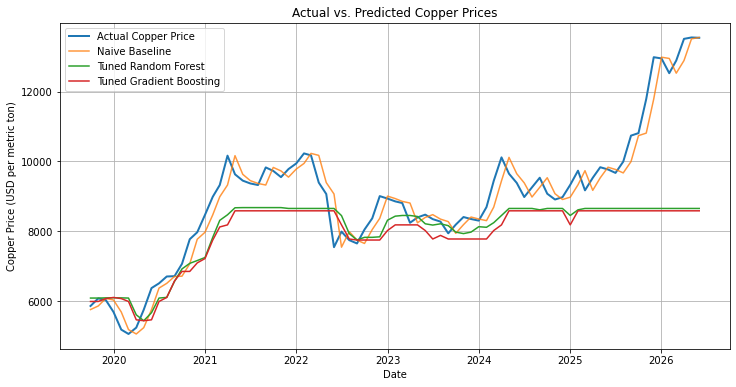

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_dates,
    y_test,
    label="Actual Copper Price",
    linewidth=2
)

plt.plot(
    test_dates,
    predictions["Naive Baseline"],
    label="Naive Baseline",
    alpha=0.8
)

plt.plot(
    test_dates,
    predictions["Tuned Random Forest"],
    label="Tuned Random Forest"
)

plt.plot(
    test_dates,
    predictions["Tuned Gradient Boosting"],
    label="Tuned Gradient Boosting"
)

plt.title("Actual vs. Predicted Copper Prices")
plt.xlabel("Date")
plt.ylabel("Copper Price (USD per metric ton)")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
test_dates = (
    data["Date"].iloc[split_idx:]
    + pd.offsets.MonthBegin(1)
)